# Local Import Requirements

In [1]:
import os
os.environ['DRJIT_LIBLLVM_PATH'] = '/usr/lib/x86_64-linux-gnu/libLLVM-20.so'
import drjit as drjit

%env DRJIT_LIBLLVM_PATH="/usr/lib/x86_64-linux-gnu/libLLVM-20.so"

env: DRJIT_LIBLLVM_PATH="/usr/lib/x86_64-linux-gnu/libLLVM-20.so"


In [2]:
import numpy as np
import tensorflow as tf

import sionna
# Import or install Sionna
try:
    import sionna.rt
except ImportError as e:
    import os
    os.system("pip install sionna-rt")
    import sionna.rt

# Other imports
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
from scipy import constants

no_preview = False # Toggle to False to use the preview widget
import mitsuba as mi
# mi.set_variant("cuda_rgb")
# Import relevant components from Sionna RT
from sionna.rt import load_scene, PlanarArray, Transmitter, Receiver, Camera,\
                      PathSolver, RadioMapSolver, subcarrier_frequencies

2026-03-07 10:29:26.960149: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
import inspect
import sionna.rt.path_solvers.sb_candidate_generator as sb
print(inspect.getfile(sb))

/path/to/sionna-venv/lib/python3.12/site-packages/sionna/rt/path_solvers/sb_candidate_generator.py


In [4]:
print(tf.config.list_physical_devices())
print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [31]:
import gc
import pickle

# Calculate Transmitter Positions, Beam Angles

In [29]:
# 250 m 
# Using orbital pass with constant x-plane
d = 250
rx_pos_sionna = np.array([35, 35, 10])

SIONNA_10_DEG = rx_pos_sionna + [d*np.cos(10*np.pi/180), 0, d*np.sin(10*np.pi/180)]
# SIONNA_50_DEG = rx_pos_sionna + [d*np.cos(50*np.pi/180), 0, d*np.sin(50*np.pi/180)]
SIONNA_90_DEG = rx_pos_sionna + [0, 0, d]

sionna_250m = [SIONNA_10_DEG,  SIONNA_90_DEG]


# 1km 
# Using orbital pass with constant x-plane
d = 1000

SIONNA_20_DEG = rx_pos_sionna + [d*np.cos(20*np.pi/180), 0, d*np.sin(20*np.pi/180)]
SIONNA_50_DEG = rx_pos_sionna + [d*np.cos(50*np.pi/180), 0, d*np.sin(50*np.pi/180)]
SIONNA_90_DEG = rx_pos_sionna + [0, 0, d]

sionna_1km = [SIONNA_20_DEG, SIONNA_50_DEG, SIONNA_90_DEG]

# LEO km 
# Using orbital pass with constant x-plane
d = [2_703_801, 698_920, 550_000]

SIONNA_20_DEG = rx_pos_sionna + [d[0]*np.cos(20*np.pi/180), 0, d[0]*np.sin(20*np.pi/180)]
SIONNA_50_DEG = rx_pos_sionna + [d[1]*np.cos(50*np.pi/180), 0, d[1]*np.sin(50*np.pi/180)]
SIONNA_90_DEG = rx_pos_sionna + [0, 0, d[2]]

sionna_LEO = [SIONNA_20_DEG, SIONNA_50_DEG, SIONNA_90_DEG]

In [514]:
print(np.linalg.norm(sionna_LEO[1] - rx_pos_sionna))

698920.0


In [ ]:
# Calculate beam angle to illuminate scene as function of elevation angle and distance

min_radius = np.sqrt(503**2 + 306**2)

# # angle to illuminate r = min_radius circle area
angle = lambda dist, elev: np.arctan(np.sqrt((np.pi*min_radius**2)*np.sin(elev*np.pi/180)/(np.pi*dist**2)))
# # using distance from origin, illuminate scene
angle_250 = np.arctan(50/250) # making beam angle wider for closer scene

angle_1k = np.arctan(50/1000)

angle_leo = np.arctan(50/550_000)
# sionna_250_angles = [angle(np.linalg.norm(sionna_250m[0]), 25), 
#                      angle(np.linalg.norm(sionna_250m[1]), 55), 
#                      angle(np.linalg.norm(sionna_250m[2]), 90)]


# sionna_1km_angles = [angle(np.linalg.norm(sionna_1km[0]), 25), 
#                      angle(np.linalg.norm(sionna_1km[1]), 55), 
#                      angle(np.linalg.norm(sionna_1km[2]), 90)]

# sionna_leo_angles = [angle(np.linalg.norm(sionna_LEO[0]), 25), 
#                      angle(np.linalg.norm(sionna_LEO[1]), 55), 
#                      angle(np.linalg.norm(sionna_LEO[2]), 90)]

In [34]:
# print(sionna_1km_angles)
# print(sionna_leo_angles)
print(angle_1k)
print(angle_leo)
# print(min_radius)

0.049958395721942765
9.090909065865264e-05


# Helper Functions

In [35]:
def mean_and_variance(taus, amps):
    tau_m = []
    tau_rms = []

    for i, t in enumerate(taus):
        t = np.asarray(t)
        a = np.asarray(amps[i])

        idx = np.argsort(t)
        t = t[idx]
        a = a[idx]

        tau0 = t[0]

        P = np.abs(a)**2          # power weights
        den = np.sum(P)
        if den == 0:
            tau_m.append(np.nan)
            tau_rms.append(np.nan)
            continue

        dt = t - tau0
        m = np.sum(dt * P) / den
        v = np.sum((dt - m)**2 * P) / den

        tau_m.append(m)
        tau_rms.append(np.sqrt(v))

    return tau_m, tau_rms

In [36]:
f = 11.7e9  # 11 GHz

eps_l = 3.1686 + 28.938/(1+1j*(f/18))-1j*(0.5672/f)
epsilon_0 = constants.epsilon_0
con = max(0,np.imag(eps_l)*2*np.pi*f*epsilon_0)


sionna.rt.radio_materials.itu.ITU_MATERIALS_PROPERTIES["tree"] = {
    (1.0, 100.0): (np.real(eps_l), 0.0, con, 0.0)  # (a, b, c, d) where εr=a*f^b, σ=c*f^d
}

sionna.rt.radio_materials.itu_material.ITURadioMaterial.ITU_MATERIAL_COLORS["tree"] = (
    0.2, 0.6, 0.2,  # Green color
)

In [37]:
# need to define materials on 10-12 GHz for ku band

sionna.rt.radio_materials.itu.ITU_MATERIALS_PROPERTIES["medium_dry_ground"] = {
    (1.0, 13.0): (15, -0.1, 0.035, 1.63)  # (a, b, c, d) where εr=a*f^b, σ=c*f^d
}


sionna.rt.radio_materials.itu.ITU_MATERIALS_PROPERTIES["wet_ground"] = {
    (1.0, 13.0): (30, -0.4, 0.15, 1.3)  # (a, b, c, d) where εr=a*f^b, σ=c*f^d
}

# Change colors for visualization
sionna.rt.radio_materials.itu_material.ITURadioMaterial.ITU_MATERIAL_COLORS["metal"] = (
    0.1, 0.1, 0.1,  # Dark Gray color
)

sionna.rt.radio_materials.itu_material.ITURadioMaterial.ITU_MATERIAL_COLORS["concrete"] = (
    0.6, 0.5, 0.3,  # Beige color
)

sionna.rt.radio_materials.itu_material.ITURadioMaterial.ITU_MATERIAL_COLORS["medium_dry_ground"] = (
    0.7, 0.7, 0.7,  # Light Gray color
)
sionna.rt.radio_materials.itu_material.ITURadioMaterial.ITU_MATERIAL_COLORS["wet_ground"] = (
    0.0, 0.1, 0.6,  # Blue color
)

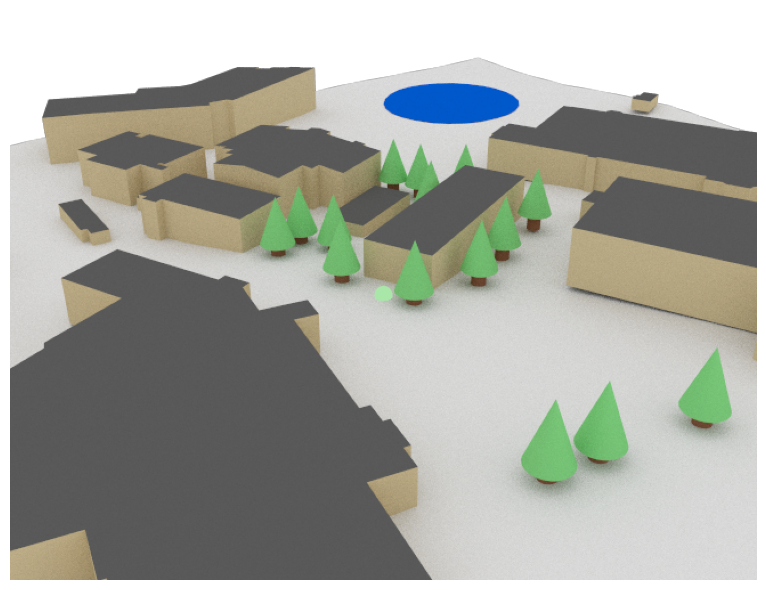

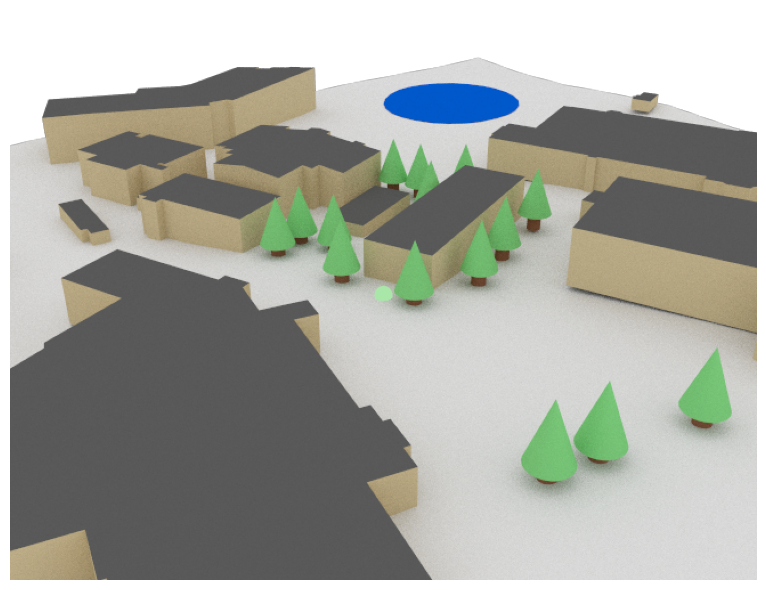

In [38]:
scene = load_scene("./sieg_scene/sieg.xml", merge_shapes=False)
scene.frequency = f  # 11.7 GHz (Ku-band downlink)
mat = scene.get("itu_concrete")
mat.scattering_coefficient = 0.4
mat.scattering_pattern = LambertianPattern()

# Create Transmitter
scene.tx_array = PlanarArray(
    num_rows=1, # of rows
    num_cols=1, # of columns
    vertical_spacing=0.5, # in wavelengths
horizontal_spacing=0.5, # in wavelengths
pattern="iso", # Antenna pattern
polarization="V" # Vertical polarization
)

tx = Transmitter(
name="sat_tx",
position=[100, 100, 250]
)
scene.add(tx)

tx.power_dbm = 43 # Transmit power in dBm

# Create Receiver
scene.rx_array = PlanarArray(
num_cols=1, 
num_rows=1,
vertical_spacing=0.5,
horizontal_spacing=0.5,
pattern="iso",
polarization="V")


rx = Receiver(
    name=f"ue_1",
    position= [35, 35, 10],
    orientation=[0.0, 0.0, 0.0])
scene.add(rx)  

tx.look_at([0, 0, 0])  # Pointing to the center of the scene


cam = Camera(position=[150,200,120], look_at=[35, 35, 10])
scene.render(camera=cam)

# 250 m Link Distance

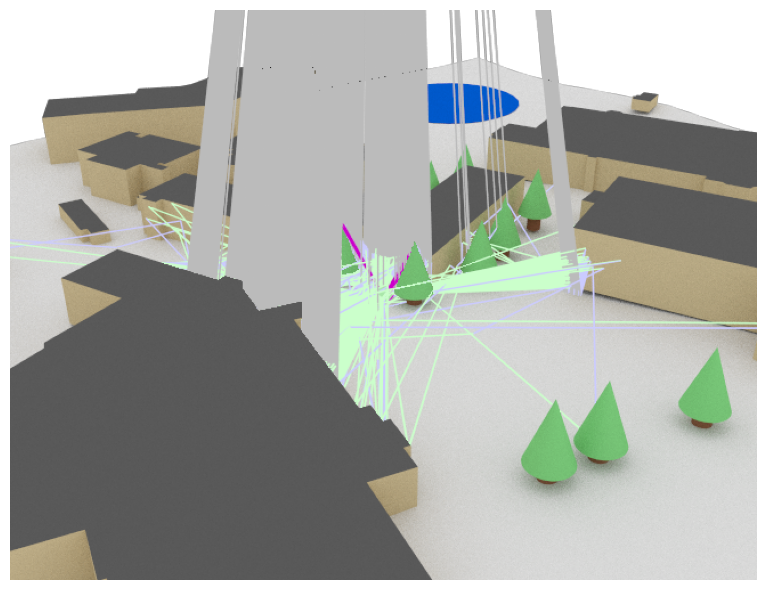

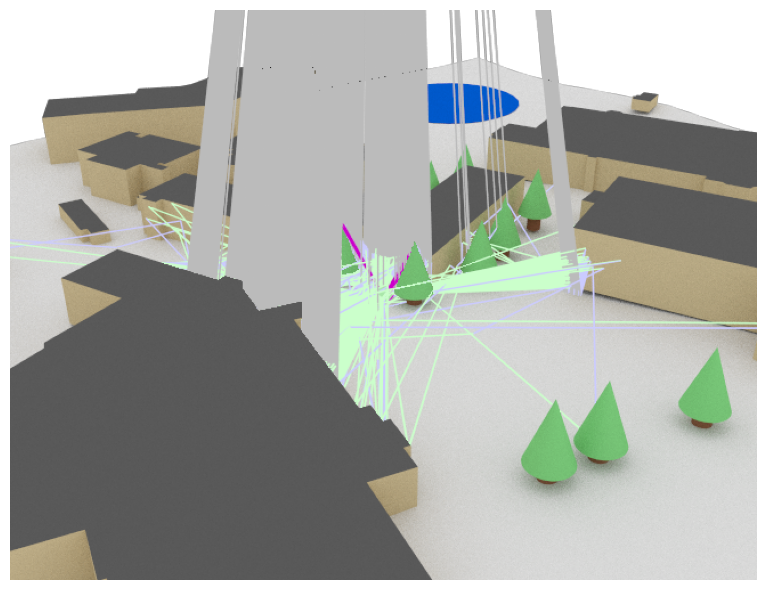

In [59]:
f = 11.7e9
# loop_taus = []
# loop_amps = []
# loop_verts = []
# loop_obj = []
# loop_int = []
# # for j in range(50):
sionna_taus_250 = []
sionna_amps_250 = []
sionna_verts_250 = []
sionna_obj_250 = []
sionna_int_250 = []

for i, tx_position in enumerate(sionna_250m):

    scene = load_scene("./sieg_scene/sieg.xml", merge_shapes=False)
    scene.frequency = f  # 11.7 GHz (Ku-band downlink)
    mat = scene.get("itu_concrete")
    mat.scattering_coefficient = 0.4
    mat.scattering_pattern = LambertianPattern()

    # Create Transmitter
    scene.tx_array = PlanarArray(
        num_rows=1, # of rows
        num_cols=1, # of columns
        vertical_spacing=0.5, # in wavelengths
        horizontal_spacing=0.5, # in wavelengths
        pattern="iso", # Antenna pattern
        polarization="V" # Vertical polarization
    )

    tx = Transmitter(
        name="sat_tx",
        position=tx_position
    )
    scene.add(tx)

    tx.power_dbm = 43 # Transmit power in dBm

    # Create Receiver
    scene.rx_array = PlanarArray(
        num_cols=1, 
        num_rows=1,
        vertical_spacing=0.5,
        horizontal_spacing=0.5,
        pattern="iso",
        polarization="V")


    rx = Receiver(
            name=f"ue_1",
            position= rx_pos_sionna,
            orientation=[0.0, 0.0, 0.0])
    scene.add(rx)  

    tx.look_at(rx_pos_sionna)  # Pointing to the center of the scene

    # Maximize number of samples
    num_samples = (2**32 - 1)//64 # 2^24 -1


    # Flush memory, having problems with allocation on repeated runs
    for name in ["paths", "amp", "tau", "paths_buffer"]:
        if name in globals():
            del globals()[name]

    gc.collect()
    drjit.flush_malloc_cache()
    drjit.eval()

    p_solver  = PathSolver()

    # Compute propagation paths
    seed = drjit.cuda.ad.UInt(np.random.randint(1,100000))
    paths = p_solver(scene=scene,
                        max_depth=5,
                        los=True,
                        specular_reflection=True,
                        diffuse_reflection=True,
                        refraction=False,
                        diffraction=True,
                        synthetic_array=False,
                        max_num_paths_per_src=50_000,
                        samples_per_src=1_000_000,
                        seed=seed,
                        beamforming=True,
                        beam_angle=angle_250)
    amp, tau = paths.cir(normalize_delays=False, out_type="numpy")

    t = tau[0,0,0,0,:] #in seconds
    amp = np.abs(amp)[0,0,0,0,:,0]
    vertices = paths.vertices.numpy()
    objects = paths.objects.numpy()
    interactions = paths.interactions.numpy()

    # Shape: [max_depth, num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths, 3]
    # vertices = paths.vertices.numpy()

    # Extract vertices for specific path
    vertices = vertices[:, 0, 0, 0, 0, :, :]
    objects = objects[:,0,0,0,:,:]

    sionna_taus_250.append(t)
    sionna_amps_250.append(amp)
    sionna_verts_250.append(vertices)
    sionna_obj_250.append(objects)
    sionna_int_250.append(interactions)

#     loop_taus.append(sionna_taus_1k)
#     loop_amps.append(sionna_amps_1k)
#     loop_verts.append(sionna_verts_1k)
#     loop_obj.append(sionna_obj_1k)
#     loop_int.append(sionna_int_1k)

cam = Camera(position=[150,200,120], look_at=rx_pos_sionna)
scene.render(camera=cam, paths=paths)


In [41]:
print(len(sionna_taus_250[0]), len(sionna_taus_250[1]))
# print(sionna_verts_1k[0].shape)

6482 4312


In [42]:
# Prune invalid paths(not sure why this happens)
# valid = np.where(sionna_taus_1k[0] > 0)
# valid2 = np.where(sionna_obj_1k[0][])
for i in range(2):
    valid = np.where(sionna_taus_250[i] > 0)
    
    sionna_taus_250[i] = sionna_taus_250[i][valid]
    sionna_amps_250[i] = sionna_amps_250[i][valid]
    sionna_verts_250[i] = sionna_verts_250[i][:, valid, :]
    sionna_obj_250[i] = sionna_obj_250[i][:, :, valid]
    

In [43]:
mean, variance = mean_and_variance(sionna_taus_250, sionna_amps_250)

print(mean)
print(variance)

[3.3029675e-08, 1.0706238e-08]
[7.612848e-08, 3.0633345e-08]


In [348]:
# print(sionna_verts_250[2].shape)

for i in range(3):
    verts = sionna_verts_250[i][:,0,:,:]
    avg_depth = 0
    for j in range(len(verts[0,:,:])):
        k = 0
        while k < 5 and not all(np.isclose([0.0, 0.0, 0.0], verts[k, j, :])):
            avg_depth += 1
            k+= 1
    print("Average Path Depth: ", avg_depth/len(verts[0,:,:]))
            

Average Path Depth:  1.4917486706826808
Average Path Depth:  1.3111555865668068
Average Path Depth:  1.295005006348256


In [57]:
t_idx = np.argmin(sionna_taus_250[1])
print(np.argmin(sionna_taus_250[1]), np.argmax(db_250[1]))

print(sionna_verts_250[0][:, :, np.argmax(db_250[0]), :])

1088 1088
[[[26.921133 31.332575 13.412234]]

 [[ 0.        0.        0.      ]]

 [[ 0.        0.        0.      ]]

 [[ 0.        0.        0.      ]]

 [[ 0.        0.        0.      ]]]


In [44]:
db_250 = [20*np.log10(i) for i in sionna_amps_250]

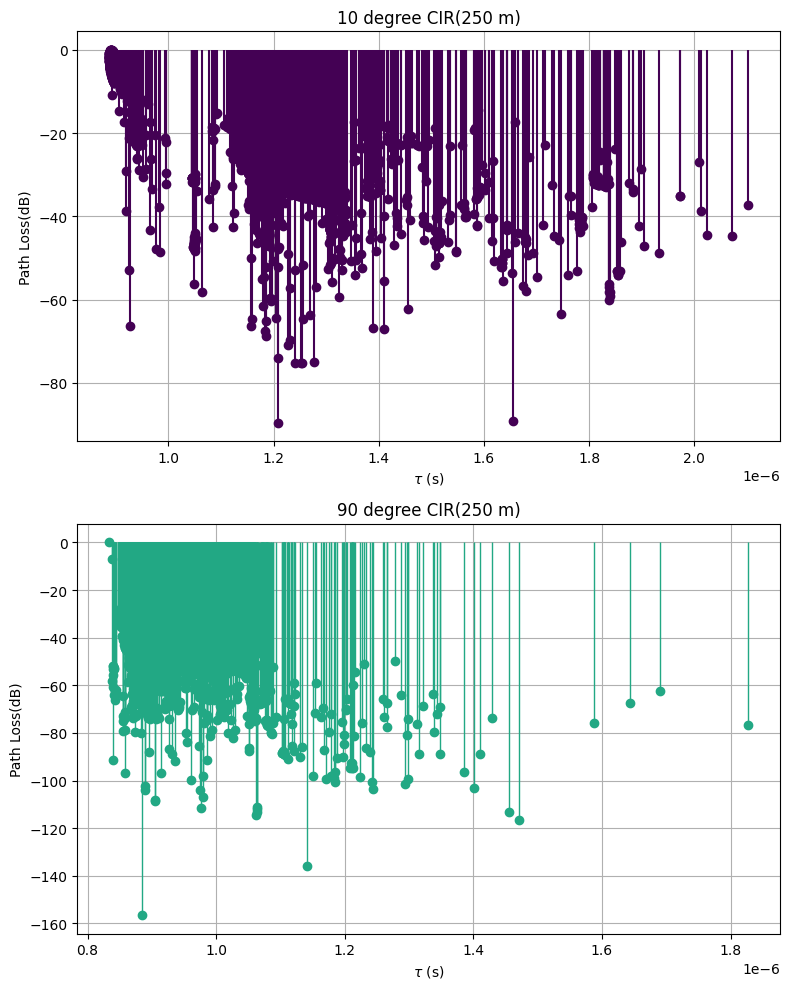

In [47]:
idx_10 = np.argsort(db_250[0])
idx_90 = np.argsort(db_250[1])
# idx_90 = np.argsort(db_250[2])

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(8, 10)
)

cmap = mpl.colormaps['viridis']
C = cmap(np.linspace(0, 1, 6))

plt.subplot(2,1,1)


markerline, stemlines, baseline = plt.stem(sionna_taus_250[0][idx_10], 
                                           db_250[0][idx_10]-np.max(db_250[0]),basefmt=" ", label='10 degree')


plt.setp(markerline, color=C[0], markersize=6)
plt.setp(stemlines, color=C[0], linewidth=1.5)
plt.title(f"10 degree CIR(250 m)")
plt.grid()
plt.ylabel(r"Path Loss(dB)")
plt.xlabel(r"$\tau$ (s)")
# plt.xlim(0.5e-6, 3e-6)

plt.subplot(2,1,2)
markerline, stemlines, baseline = plt.stem(sionna_taus_250[1][idx_90], 
                                           db_250[1][idx_90]-np.max(db_250[1]),basefmt=" ", label='90 degree')


plt.setp(markerline, color=C[3], markersize=6)
plt.setp(stemlines, color=C[3], linewidth=1.0)

plt.title(f"90 degree CIR(250 m)")
plt.grid()
plt.ylabel(r"Path Loss(dB)")
plt.xlabel(r"$\tau$ (s)")
# plt.xlim(0.5e-6, 3e-6)



# plt.xlim(800, 1200)

# plt.legend()
plt.tight_layout()
plt.show()

# 1km Link Distances

In [419]:
import gc
import pickle

In [420]:
from sionna.rt import LambertianPattern

scene = load_scene("./wharf_scene_v3/canarywharf3.xml", merge_shapes=False)
# print(scene.objects)

obj = scene.get("elm__229")
mat = obj.radio_material
mat.scattering_coefficient = 0.4
mat.scattering_pattern = LambertianPattern()
print(mat)

ITURadioMaterial type=concrete
                 eta_r=5.240
                 sigma=0.123
                 thickness=0.100
                 scattering_coefficient=0.400
                 xpd_coefficient=0.000


In [421]:
obj = scene.get("elm__227")
mat2 = obj.radio_material
print(mat2)

ITURadioMaterial type=concrete
                 eta_r=5.240
                 sigma=0.123
                 thickness=0.100
                 scattering_coefficient=0.400
                 xpd_coefficient=0.000


1 km with Valid scattering

In [491]:
f = 11.7e9
loop_taus = []
loop_amps = []
loop_verts = []
loop_obj = []
loop_int = []
for j in range(1):
    sionna_taus_1k = []
    sionna_amps_1k = []
    sionna_verts_1k = []
    sionna_obj_1k = []
    sionna_int_1k = []

    for i, tx_position in enumerate(sionna_1km):

        scene = load_scene("./wharf_scene_v3/canarywharf3.xml", merge_shapes=False)
        scene.frequency = f  # 11.7 GHz (Ku-band downlink)
        obj = scene.get("elm__229")
        mat = obj.radio_material
        mat.scattering_coefficient = 0.4
        mat.scattering_pattern = LambertianPattern()

        # Create Transmitter
        scene.tx_array = PlanarArray(
            num_rows=1, # of rows
            num_cols=1, # of columns
            vertical_spacing=0.5, # in wavelengths
            horizontal_spacing=0.5, # in wavelengths
            pattern="iso", # Antenna pattern
            polarization="V" # Vertical polarization
        )

        tx = Transmitter(
            name="sat_tx",
            position=tx_position
        )
        scene.add(tx)

        tx.power_dbm = 43 # Transmit power in dBm

        # Create Receiver
        scene.rx_array = PlanarArray(
            num_cols=1, 
            num_rows=1,
            vertical_spacing=0.5,
            horizontal_spacing=0.5,
            pattern="iso",
            polarization="V")


        rx = Receiver(
                name=f"ue_1",
                position= rx_pos_sionna,
                orientation=[0.0, 0.0, 0.0])
        scene.add(rx)  

        tx.look_at(rx_pos_sionna)  # Pointing to the center of the scene

        # Maximize number of samples
        num_samples = (2**32 - 1)//64 # 2^24 -1


        # Flush memory, having problems with allocation on repeated runs
        for name in ["paths", "amp", "tau", "paths_buffer"]:
            if name in globals():
                del globals()[name]

        gc.collect()
        drjit.flush_malloc_cache()
        drjit.eval()

        p_solver  = PathSolver()

        # Compute propagation paths
        seed = drjit.cuda.ad.UInt(np.random.randint(1,100000))
        paths = p_solver(scene=scene,
                            max_depth=5,
                            los=True,
                            specular_reflection=True,
                            diffuse_reflection=True,
                            refraction=False,
                            diffraction=True,
                            synthetic_array=False,
                            max_num_paths_per_src=1_000_000,
                            samples_per_src=num_samples,
                            seed=seed,
                            beamforming=True,
                            beam_angle=angle_1k)
        amp, tau = paths.cir(normalize_delays=False, out_type="numpy")

        t = tau[0,0,0,0,:] #in seconds
        amp = np.abs(amp)[0,0,0,0,:,0]
        vertices = paths.vertices.numpy()
        objects = paths.objects.numpy()
        interactions = paths.interactions.numpy()

        # Shape: [max_depth, num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths, 3]
        # vertices = paths.vertices.numpy()

        # Extract vertices for specific path
        vertices = vertices[:, 0, 0, 0, 0, :, :]
        objects = objects[:,0,0,0,:,:]

        sionna_taus_1k.append(t)
        sionna_amps_1k.append(amp)
        sionna_verts_1k.append(vertices)
        sionna_obj_1k.append(objects)
        sionna_int_1k.append(interactions)

    loop_taus.append(sionna_taus_1k)
    loop_amps.append(sionna_amps_1k)
    loop_verts.append(sionna_verts_1k)
    loop_obj.append(sionna_obj_1k)
    loop_int.append(sionna_int_1k)


In [492]:
print(len(sionna_taus_1k[0]), len(sionna_taus_1k[1]), len(sionna_taus_1k[2]))
# print(sionna_verts_1k[0].shape)

995999 996841 997190


In [493]:
v_test = paths.vertices.numpy()
v_test= v_test[:, 0,0,0,:,:,:]
print(v_test[0,:5, :, :])


[[[332.95428   61.75351    0.      ]
  [322.6355    54.863274   0.      ]
  [329.6716    59.182705   0.      ]
  ...
  [314.07794   79.255936   0.      ]
  [327.39096   81.45232    0.      ]
  [317.10733   81.67997    0.      ]]]


In [494]:

inter = sionna_int_1k[0][:,0,0,0,0,:]
diffuse_sum = 0
for i in range(inter.shape[1]):
    if not (np.where(inter[:, i] == 2))[0].size == 0:
        diffuse_sum += 1
print(diffuse_sum)
print(inter.shape)

995991
(5, 995999)


In [495]:
# Prune invalid paths(not sure why this happens)
# valid = np.where(sionna_taus_1k[0] > 0)
# valid2 = np.where(sionna_obj_1k[0][])
for i in range(3):
    valid = np.where(sionna_taus_1k[i] > 0)
    
    sionna_taus_1k[i] = sionna_taus_1k[i][valid]
    sionna_amps_1k[i] = sionna_amps_1k[i][valid]
    sionna_verts_1k[i] = sionna_verts_1k[i][:, valid, :]
    sionna_obj_1k[i] = sionna_obj_1k[i][:, :, valid]
    

In [496]:
mean, variance = mean_and_variance(sionna_taus_1k, sionna_amps_1k)

print(mean)
print(variance)

[2.3852888e-08, 5.0041642e-08, 6.8166e-08]
[6.29824e-08, 7.2069575e-08, 1.0076401e-07]


In [497]:
print(len(sionna_taus_1k[0]), len(sionna_taus_1k[1]), len(sionna_taus_1k[2]))
# print(sionna_verts_1k[1][1,:,1,:])

995999 996841 997190


In [498]:
db_1k = [20*np.log10(i) for i in sionna_amps_1k]

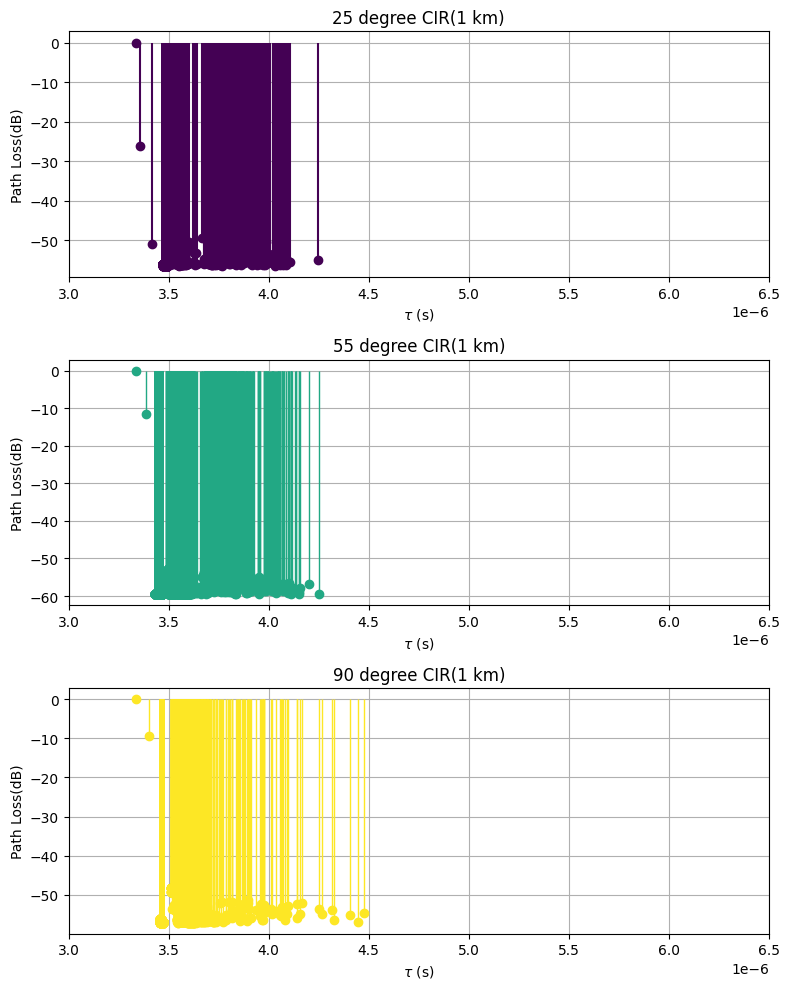

In [499]:
idx_25 = np.argsort(db_1k[0])
idx_55 = np.argsort(db_1k[1])
idx_90 = np.argsort(db_1k[2])

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(8, 10)
)

cmap = mpl.colormaps['viridis']
C = cmap(np.linspace(0, 1, 6))

plt.subplot(3,1,1)


markerline, stemlines, baseline = plt.stem(sionna_taus_1k[0][idx_25[-10000:]], 
                                           db_1k[0][idx_25[-10000:]]-np.max(db_1k[0]),basefmt=" ", label='25 degree')


plt.setp(markerline, color=C[0], markersize=6)
plt.setp(stemlines, color=C[0], linewidth=1.5)
plt.title(f"25 degree CIR(1 km)")
plt.grid()
plt.ylabel(r"Path Loss(dB)")
plt.xlabel(r"$\tau$ (s)")
plt.xlim(3e-6, 6.5e-6)

plt.subplot(3,1,2)
markerline, stemlines, baseline = plt.stem(sionna_taus_1k[1][idx_55[-10000:]], 
                                           db_1k[1][idx_55[-10000:]]-np.max(db_1k[1]),basefmt=" ", label='55 degree')


plt.setp(markerline, color=C[3], markersize=6)
plt.setp(stemlines, color=C[3], linewidth=1.0)

plt.title(f"55 degree CIR(1 km)")
plt.grid()
plt.ylabel(r"Path Loss(dB)")
plt.xlabel(r"$\tau$ (s)")
plt.xlim(3e-6, 6.5e-6)

plt.subplot(3,1,3)

markerline, stemlines, baseline = plt.stem(sionna_taus_1k[2][idx_90[-10000:]], 
                                           db_1k[2][idx_90[-10000:]]-np.max(db_1k[2]),basefmt=" ", label='90 degree')


plt.setp(markerline, color=C[5], markersize=6)
plt.setp(stemlines, color=C[5], linewidth=1.0)
# Color configuration
plt.title(f"90 degree CIR(1 km)")
plt.grid()
plt.ylabel(r"Path Loss(dB)")
plt.xlabel(r"$\tau$ (s)")

plt.xlim(3e-6, 6.5e-6)

# plt.legend()
plt.tight_layout()
plt.show()

In [155]:
objects = paths.objects.numpy()
objects = objects[:,0,0,0,:,:]
print(sionna_verts_1k[2][:, 0,1])
print(sionna_obj_1k[0].shape)
# path_objects = objects[:, rx_idx, rx_ant_idx, tx_idx, tx_ant_idx, path_idx]


[[  300.00003   100.00001     0.     ]
 [  300.        100.      -1100.     ]
 [    0.          0.          0.     ]
 [    0.          0.          0.     ]
 [    0.          0.          0.     ]]
(5, 1, 1, 120)


In [275]:
# export path information
with open("sionna_cir_1k.pkl", "wb") as f:
    pickle.dump({"taus": sionna_taus_1k, "amps": sionna_amps_1k, 
                 "vertices": sionna_verts_1k, "objects": sionna_obj_1k,
                "interactions": sionna_int_1k}, f, protocol=pickle.HIGHEST_PROTOCOL)

# LEO(550 km) Link Distances

In [562]:
f = 11.7e9
# loop_taus = []
# loop_amps = []
# loop_verts = []
# loop_obj = []
# loop_int = []
# # for j in range(50):
sionna_taus_leo = []
sionna_amps_leo = []
sionna_verts_leo = []
sionna_obj_leo = []
sionna_int_leo = []

for i, tx_position in enumerate(sionna_LEO):

    scene = load_scene("./wharf_scene_v3/canarywharf3.xml", merge_shapes=False)
    scene.frequency = f  # 11.7 GHz (Ku-band downlink)
    obj = scene.get("elm__229")
    mat = obj.radio_material
    mat.scattering_coefficient = 0.4
    mat.scattering_pattern = LambertianPattern()

    # Create Transmitter
    scene.tx_array = PlanarArray(
        num_rows=1, # of rows
        num_cols=1, # of columns
        vertical_spacing=0.5, # in wavelengths
        horizontal_spacing=0.5, # in wavelengths
        pattern="iso", # Antenna pattern
        polarization="V" # Vertical polarization
    )

    tx = Transmitter(
        name="sat_tx",
        position=tx_position
    )
    scene.add(tx)

    tx.power_dbm = 43 # Transmit power in dBm

    # Create Receiver
    scene.rx_array = PlanarArray(
        num_cols=1, 
        num_rows=1,
        vertical_spacing=0.5,
        horizontal_spacing=0.5,
        pattern="iso",
        polarization="V")


    rx = Receiver(
            name=f"ue_1",
            position= rx_pos_sionna,
            orientation=[0.0, 0.0, 0.0])
    scene.add(rx)  

    tx.look_at(rx_pos_sionna)  # Pointing to the center of the scene

    # Maximize number of samples
    num_samples = (2**32 - 1)//256 # 2^24 -1


    # Flush memory, having problems with allocation on repeated runs
    for name in ["paths", "amp", "tau", "paths_buffer"]:
        if name in globals():
            del globals()[name]

    gc.collect()
    drjit.flush_malloc_cache()
    drjit.eval()

    p_solver  = PathSolver()

    # Compute propagation paths
    seed = drjit.cuda.ad.UInt(np.random.randint(1,100000))
    paths = p_solver(scene=scene,
                        max_depth=5,
                        los=True,
                        specular_reflection=True,
                        diffuse_reflection=True,
                        refraction=False,
                        diffraction=True,
                        synthetic_array=False,
                        max_num_paths_per_src=50_000,
                        samples_per_src=1_000_000,
                        seed=seed,
                        beamforming=True,
                        beam_angle=angle_leo)
    amp, tau = paths.cir(normalize_delays=False, out_type="numpy")

    t = tau[0,0,0,0,:] #in seconds
    amp = np.abs(amp)[0,0,0,0,:,0]
    vertices = paths.vertices.numpy()
    objects = paths.objects.numpy()
    interactions = paths.interactions.numpy()

    # Shape: [max_depth, num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths, 3]
    # vertices = paths.vertices.numpy()

    # Extract vertices for specific path
    vertices = vertices[:, 0, 0, 0, 0, :, :]
    objects = objects[:,0,0,0,:,:]

    sionna_taus_leo.append(t)
    sionna_amps_leo.append(amp)
    sionna_verts_leo.append(vertices)
    sionna_obj_leo.append(objects)
    sionna_int_leo.append(interactions)

#     loop_taus.append(sionna_taus_1k)
#     loop_amps.append(sionna_amps_1k)
#     loop_verts.append(sionna_verts_1k)
#     loop_obj.append(sionna_obj_1k)
#     loop_int.append(sionna_int_1k)


In [548]:
print(len(sionna_taus_leo[0]), len(sionna_taus_leo[1]), len(sionna_taus_leo[2]))

998419 998087 998293


In [549]:
print(sionna_LEO[2])

[   300    100 550010]


In [550]:
# Prune invalid paths(not sure why this happens)
for i in range(3):
    valid = np.where(sionna_taus_leo[i] > 0)
    
    sionna_taus_leo[i] = sionna_taus_leo[i][valid]
    sionna_amps_leo[i] = sionna_amps_leo[i][valid]
    sionna_verts_leo[i] = sionna_verts_leo[i][:, valid, :]
    sionna_obj_leo[i] = sionna_obj_leo[i][:,:,valid]
    

In [551]:
mean, variance = mean_and_variance(sionna_taus_leo, sionna_amps_leo)

print(mean)
print(variance)

[2.107357e-07, 8.9834565e-08, 6.696049e-08]
[5.2474213e-08, 2.868432e-08, 5.8383764e-09]


In [552]:
print(len(sionna_taus_leo[0]), len(sionna_taus_leo[1]), len(sionna_taus_leo[2]))

998419 998087 998293


In [553]:
db_leo = [20*np.log10(i) for i in sionna_amps_leo]

In [554]:
idx_sorted = np.argsort(db_leo[0])
# print(np.argmin(sionna_taus_leo[1]))
# print(np.argmax(db_leo[1]))
print(sionna_verts_leo[1][:, :, idx_sorted[-5:], :])
print(db_leo[0][idx_sorted[-10:]])



[[[[291.52087   99.960724   0.      ]
   [291.52087   99.960724   0.      ]
   [291.52087   99.960724   0.      ]
   [291.52087   99.960724   0.      ]
   [291.52087   99.960724   0.      ]]]


 [[[  0.         0.         0.      ]
   [244.34413   99.96072   56.249184]
   [244.34413   99.96072   56.249184]
   [  0.         0.         0.      ]
   [244.34413   99.96072   56.249184]]]


 [[[  0.         0.         0.      ]
   [  0.         0.         0.      ]
   [  0.         0.         0.      ]
   [  0.         0.         0.      ]
   [  0.         0.         0.      ]]]


 [[[  0.         0.         0.      ]
   [  0.         0.         0.      ]
   [  0.         0.         0.      ]
   [  0.         0.         0.      ]
   [  0.         0.         0.      ]]]


 [[[  0.         0.         0.      ]
   [  0.         0.         0.      ]
   [  0.         0.         0.      ]
   [  0.         0.         0.      ]
   [  0.         0.         0.      ]]]]
[-164.46799 -164.45357 -164.437

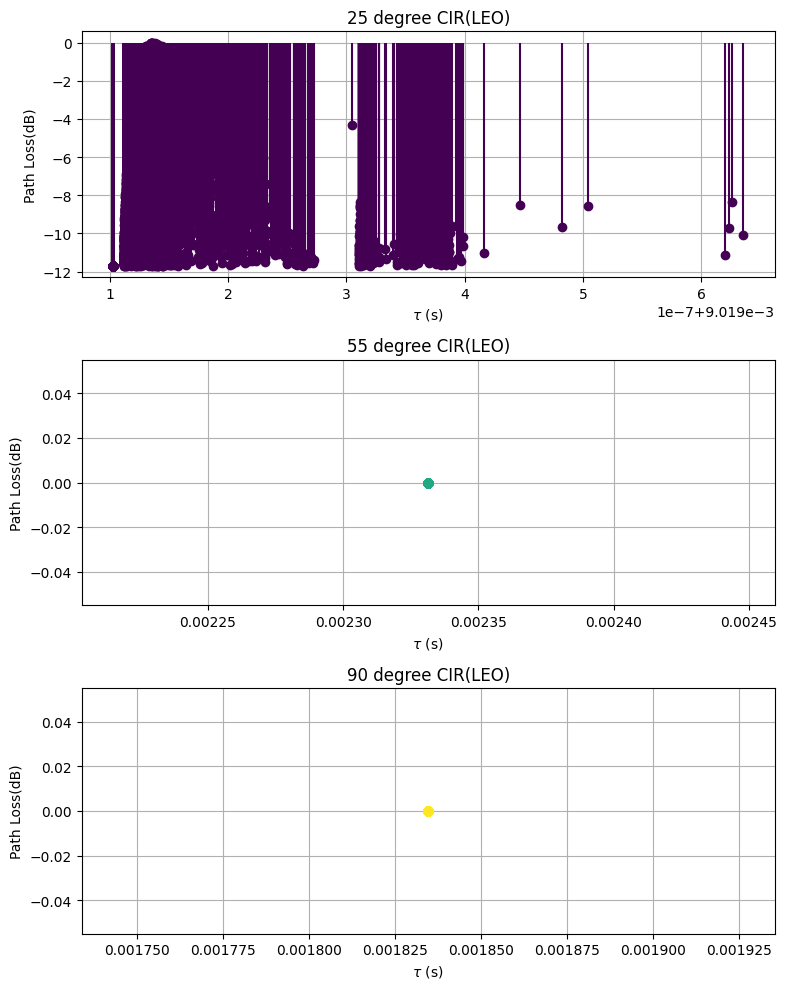

In [555]:
idx_25 = np.argsort(db_leo[0])
idx_55 = np.argsort(db_leo[1])
idx_90 = np.argsort(db_leo[2])

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(8, 10)
)

cmap = mpl.colormaps['viridis']
C = cmap(np.linspace(0, 1, 6))

plt.subplot(3,1,1)


markerline, stemlines, baseline = plt.stem(sionna_taus_leo[0][idx_25[-10000:]], 
                                           db_leo[0][idx_25[-10000:]]-np.max(db_leo[0]),basefmt=" ", label='25 degree')


plt.setp(markerline, color=C[0], markersize=6)
plt.setp(stemlines, color=C[0], linewidth=1.5)
plt.title(f"25 degree CIR(LEO)")
plt.grid()
plt.ylabel(r"Path Loss(dB)")
plt.xlabel(r"$\tau$ (s)")
# plt.xlim(1.834e-3, 1.838e-3)

plt.subplot(3,1,2)
markerline, stemlines, baseline = plt.stem(sionna_taus_leo[1][idx_55[-10000:]], 
                                           db_leo[1][idx_55[-10000:]]-np.max(db_leo[1]),basefmt=" ", label='55 degree')


plt.setp(markerline, color=C[3], markersize=6)
plt.setp(stemlines, color=C[3], linewidth=1.0)

plt.title(f"55 degree CIR(LEO)")
plt.grid()
plt.ylabel(r"Path Loss(dB)")
plt.xlabel(r"$\tau$ (s)")
# plt.xlim(1.834e-3, 1.838e-3)

plt.subplot(3,1,3)

markerline, stemlines, baseline = plt.stem(sionna_taus_leo[2][idx_90[-10000:]], 
                                           db_leo[2][idx_90[-10000:]]-np.max(db_leo[2]),basefmt=" ", label='90 degree')


plt.setp(markerline, color=C[5], markersize=6)
plt.setp(stemlines, color=C[5], linewidth=1.0)
# Color configuration
plt.title(f"90 degree CIR(LEO)")
plt.grid()
plt.ylabel(r"Path Loss(dB)")
plt.xlabel(r"$\tau$ (s)")

# plt.xlim(1.834e-3, 1.838e-3)

# plt.legend()
plt.tight_layout()
plt.show()

In [281]:
# export path information
with open("sionna_cir_leo.pkl", "wb") as f:
    pickle.dump({"taus": sionna_taus_leo, "amps": sionna_amps_leo, 
                 "vertices": sionna_verts_leo, "objects": sionna_obj_leo,
                "interactions": sionna_int_leo}, f, protocol=pickle.HIGHEST_PROTOCOL)

# Original Sionna Baseline

In [261]:
f = 11.7e9
# loop_taus = []
# loop_amps = []
# loop_verts = []
# loop_obj = []
# loop_int = []
# # for j in range(50):
reg_taus_leo = []
reg_amps_leo = []
reg_verts_leo = []
reg_obj_leo = []
reg_int_leo = []

for i, tx_position in enumerate(sionna_LEO):

    scene = load_scene("./wharf_scene_v3/canarywharf3.xml", merge_shapes=False)
    scene.frequency = f  # 11.7 GHz (Ku-band downlink)
    obj = scene.get("elm__229")
    mat = obj.radio_material
    mat.scattering_coefficient = 0.4
    mat.scattering_pattern = LambertianPattern()

    # Create Transmitter
    scene.tx_array = PlanarArray(
        num_rows=1, # of rows
        num_cols=1, # of columns
        vertical_spacing=0.5, # in wavelengths
        horizontal_spacing=0.5, # in wavelengths
        pattern="iso", # Antenna pattern
        polarization="V" # Vertical polarization
    )

    tx = Transmitter(
        name="sat_tx",
        position=tx_position
    )
    scene.add(tx)

    tx.power_dbm = 43 # Transmit power in dBm

    # Create Receiver
    scene.rx_array = PlanarArray(
        num_cols=1, 
        num_rows=1,
        vertical_spacing=0.5,
        horizontal_spacing=0.5,
        pattern="iso",
        polarization="V")


    rx = Receiver(
            name=f"ue_1",
            position= rx_pos_sionna,
            orientation=[0.0, 0.0, 0.0])
    scene.add(rx)  

    tx.look_at([0, 0, 0])  # Pointing to the center of the scene

    # Maximize number of samples
    num_samples = (2**32 - 1)//64 # 2^24 -1


    # Flush memory, having problems with allocation on repeated runs
    for name in ["paths", "amp", "tau", "paths_buffer"]:
        if name in globals():
            del globals()[name]

    gc.collect()
    drjit.flush_malloc_cache()
    drjit.eval()

    p_solver  = PathSolver()

    # Compute propagation paths
    seed = drjit.cuda.ad.UInt(np.random.randint(1,100000))
    paths = p_solver(scene=scene,
                        max_depth=5,
                        los=True,
                        specular_reflection=True,
                        diffuse_reflection=True,
                        refraction=False,
                        diffraction=True,
                        synthetic_array=False,
                        max_num_paths_per_src=800_000,
                        samples_per_src=num_samples,
                        seed=seed,
                        beamforming=False)
    amp, tau = paths.cir(normalize_delays=False, out_type="numpy")

    t = tau[0,0,0,0,:] #in seconds
    amp = np.abs(amp)[0,0,0,0,:,0]
    vertices = paths.vertices.numpy()
    objects = paths.objects.numpy()
    interactions = paths.interactions.numpy()

    # Shape: [max_depth, num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths, 3]
    # vertices = paths.vertices.numpy()

    # Extract vertices for specific path
    vertices = vertices[:, 0, 0, 0, 0, :, :]
    objects = objects[:,0,0,0,:,:]

    reg_taus_leo.append(t)
    reg_amps_leo.append(amp)
    reg_verts_leo.append(vertices)
    reg_obj_leo.append(objects)
    reg_int_leo.append(interactions)

#     loop_taus.append(sionna_taus_1k)
#     loop_amps.append(sionna_amps_1k)
#     loop_verts.append(sionna_verts_1k)
#     loop_obj.append(sionna_obj_1k)
#     loop_int.append(sionna_int_1k)


In [262]:
print(len(reg_taus_leo[0]),len(reg_taus_leo[1]),len(reg_taus_leo[2]))

2 4 2


In [173]:
MIN_LAT = 51.502
MIN_LON = -0.027
MAX_LAT = 51.5075
MAX_LON = -0.0125

# Longitude [-0.027, -0.0125]
# Latitude [51.502, 51.5075]

def geographic_to_cartesian(lat, lon, alt=0):
    """Convert geographic coordinates to Cartesian coordinates. Needed to assure
    cross-compatibility with MATLAB and Sionna RT, which uses Cartesian coordinates."""

     # Midpoint origin (degrees)
    lat0 = 0.5 * (MIN_LAT + MAX_LAT)
    lon0 = 0.5 * (MIN_LON + MAX_LON)

    dlat = lat - lat0
    dlon = lon - lon0

    # Meters per degree (simple approximation)
    meters_per_deg_lat = 111_132.0
    meters_per_deg_lon = 111_320.0 * np.cos(np.radians(lat0))

    east  = dlon * meters_per_deg_lon
    north = dlat * meters_per_deg_lat
    up    = alt
    return np.array([east, north, up])

In [179]:
scene = load_scene("./wharf_scene_v3/canarywharf3.xml", merge_shapes=False)
# scene.preview()
obj = scene.get("elm__229")
mat = obj.radio_material
mat.scattering_coefficient = 0.4
mat.scattering_pattern = LambertianPattern()
scene.frequency = 11.7e9  


scene.tx_array = PlanarArray(num_rows=1,
                             num_cols=1,
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="iso",
                             polarization="V")

# Configure antenna array for all receivers
scene.rx_array = PlanarArray(num_rows=1,
                             num_cols=1,
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="iso",
                             polarization="cross")

# Create transmitter

tx_position = geographic_to_cartesian(51.50375, -0.01843, alt=10)
# Create a transmitter

tx = Transmitter(name="tx",
                 position=tx_position,
                 display_radius=10)

# Add transmitter instance to scene
scene.add(tx)
tx.power_dbm = 43 # Transmit power in dBm


rx_position = geographic_to_cartesian(51.50216, -0.01769, alt=5)
# print("Receiver position (x,y,z) in meters:", rx_position)
# Create a receiver
rx = Receiver(name="rx",
              position=rx_position,
              display_radius=10)

# Add receiver instance to scene
scene.add(rx)

tx.look_at(rx) # Transmitter points towards receiver
p_solver  = PathSolver()
    # Compute propagation paths
paths = p_solver(scene=scene,
                     max_depth=5,
                     los=True,
                     specular_reflection=True,
                     diffuse_reflection=True,
                     refraction=False,
                     diffraction=True,
                     synthetic_array=False,
                     max_num_paths_per_src=800_000,
                     samples_per_src=2**24)
num_paths = paths.a[0][0,0,0,0,:].shape[0]
# print(f"Number of paths between tx and rx: {num_paths}")

a, tau = paths.cir(normalize_delays=False, out_type="numpy")

t = tau[0,0,0,0,:]/1e-9 # Scale to ns
a_abs = np.abs(a)[0,0,0,0,:,0]

interactions = paths.interactions.numpy()
    
# interactions = interactions[:,0,0,:]

In [185]:
print(interactions[:, 0, :, 0,0,:])

[[[1 1 1 1 1 1 1 1 1 1 1 1 1]
  [1 1 1 1 1 1 1 1 1 1 1 1 1]]

 [[0 1 1 1 1 1 1 1 1 1 1 1 1]
  [0 1 1 1 1 1 1 1 1 1 1 1 1]]

 [[0 0 0 1 1 1 1 1 1 0 1 1 1]
  [0 0 0 1 1 1 1 1 1 0 1 1 1]]

 [[0 0 0 1 0 1 1 1 0 0 1 0 1]
  [0 0 0 1 0 1 1 1 0 0 1 0 1]]

 [[0 0 0 0 0 0 1 1 0 0 0 0 1]
  [0 0 0 0 0 0 1 1 0 0 0 0 1]]]
